# Introduction

This independent project explores the fine-tuning of a YOLO object detection model using the Ultralytics Construction-PPE Dataset. The primary objective is to evaluate the model's ability to detect personal protective equipment (PPE) and identify potential safety-related conditions in construction environments.

The project involves dataset inspection and preprocessing, model training, and performance evaluation using object detection metrics, including precision, recall, and mean Average Precision (mAP).

**Research Perspective**

Beyond model implementation, this project aims to examine how dataset characteristics, class distribution, and visual variability influence object detection performance. Particular attention is given to class-specific results and potential limitations in detecting different PPE categories.

The evaluation is intended to provide insights into the reliability of YOLO-based detection systems for construction site safety monitoring and identify potential areas for improvement.

Dataset: Ultralytics Construction-PPE Dataset
Framework: Ultralytics YOLO
Task: Object Detection and Model Fine-Tuning

# Dataset description

Dataset classes

0.	helmet

1.	gloves

2.	vest

3.	boots

4.	goggles

5.	Person

6.	no_helmet

7.	no_goggle

8.	no_gloves

9.	no_boots

10.	forklift

11.	no_vest


# Dataset import and structure

Imports and versions

In [ ]:
!pip install -q ultralytics

import ultralytics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics.data.utils import check_det_dataset
import os
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter


print("Ultralytics version:", ultralytics.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.212
NumPy version: 2.4.6
Pandas version: 2.2.3


Chack data and create paths

In [ ]:
data = check_det_dataset("construction-ppe.yaml")
print("Dataset downloaded and verified")

dataset_path = Path(data["path"])
print("Dataset path:", dataset_path)

print("Number of classes:", data["nc"])
print("Class names:", data["names"])

train_img_path = Path(data["train"])
print("Training images:", train_img_path)

val_img_path = Path(data["val"])
print("Validation images:", val_img_path)


WARNING ⚠️ Dataset 'construction-ppe.yaml' images not found, missing path '/content/datasets/construction-ppe/images/val'
Unzipping /content/datasets/construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2004/2004 411.7files/s 4.9s
Dataset download success ✅ (14.6s), saved to /content/datasets

Dataset downloaded and verified
Dataset path: /content/datasets/construction-ppe
Number of classes: 12
Class names: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}
Training images: /content/datasets/construction-ppe/images/train
Validation images: /content/datasets/construction-ppe/images/val


Dataset path content

In [ ]:
for item in sorted(dataset_path.iterdir()):
    print(item.name)

LICENSE.txt
README.md
data.yaml
images
labels
manifest.jsonl


# Class distribution

Count number of objects per class

In [ ]:
class_names = {
    0: 'helmet',
    1: 'gloves',
    2: 'vest',
    3: 'boots',
    4: 'goggles',
    5: 'Person',
    6: 'no_helmet',
    7: 'no_goggle',
    8: 'no_gloves',
    9: 'no_boots',
    10: 'forklift',
    11: 'no_vest'
}


def count_instances(split):
    labels_dir = dataset_path / "labels" / split
    counts = Counter()

    for file in labels_dir.glob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if values:
                    class_id = int(values[0])
                    counts[class_id] += 1

    return counts

train_counts = count_instances("train")
val_counts = count_instances("val")


Table of class distribution

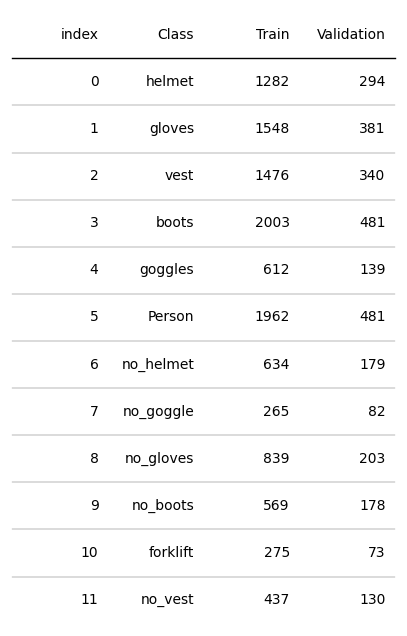

In [ ]:
!pip install plottable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plottable import Table

df = pd.DataFrame({
    "Class": list(class_names.values()),
    "Train": [train_counts[i] for i in class_names],
    "Validation": [val_counts[i] for i in class_names]
})

fig, ax = plt.subplots(figsize=(5, 8))
tab = Table(df)

plt.show()

Class distribution graphed

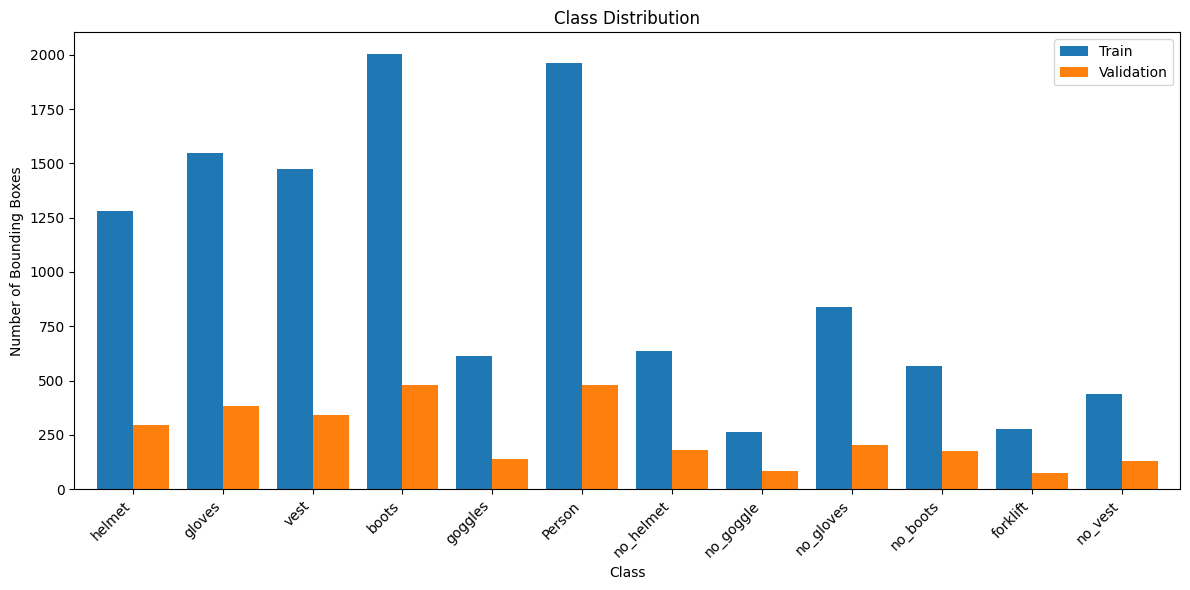

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df.set_index("Class").plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

The classes are imbalanced. It is important to train a model with enough and diverse examples of each class. Later, doing the model, is going to be seen if there has to be some resampling methods

# Fine-tuning YOLO

## First model



### Training

This model has the hiperparameters:

imgsz=640

batch=16

In [ ]:
from ultralytics import YOLO

model1 = YOLO("yolo26n.pt")

yaml = Path(data["path"])

results = model1.train(
    data=yaml,
    epochs=100,
    patience=20,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/construction-ppe, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False,

#### Evaluate and save weights

In [ ]:
from ultralytics import YOLO
from ultralytics.utils.plotting import plot_results
from google.colab import drive
from IPython.display import Image, display
import os
import shutil

drive.mount('/content/drive')

save_dir1 = model1results.save_dir

plot_results(file=os.path.join(save_dir1, "results.csv"))

display(Image(filename=os.path.join(save_dir1, "results.png")))

model1weights = YOLO(
    os.path.join(save_dir1, "weights", "best.pt")
)

metrics = model2weights.val(
    data=yaml,
    imgsz=960
)

destination = "/content/drive/MyDrive/PPE_Construction_YOLO/weights"

os.makedirs(destination, exist_ok=True)

shutil.copy(
    os.path.join(save_dir2, "weights", "best.pt"),
    os.path.join(destination, "model1.pt")
)

print("Saved files:", os.listdir(destination))

In [ ]:
from ultralytics.utils.plotting import plot_results
from IPython.display import Image, display
import os

save_dir1 = model1results.save_dir

plot_results(file=os.path.join(save_dir1, "results1.csv"))

display(Image(filename=os.path.join(save_dir1, "results1.png")))

### Results

In [ ]:
from ultralytics import YOLO

model1weights = YOLO(
    os.path.join(save_dir1, "weights", "best.pt")
)

metrics = model1weights.val(
    data=yaml,
    imgsz=960
)

#### Plotted metrics

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

names = metrics.names
class_ids = metrics.box.ap_class_index

class_names = [names[int(i)] for i in class_ids]

map50 = metrics.box.ap50
map5095 = metrics.box.maps

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, map50, width, label="mAP50")
plt.bar(x + width/2, map5095, width, label="mAP50-95")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Performance by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
precision = metrics.box.p
recall = metrics.box.r

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, precision, width, label="Precision")
plt.bar(x + width/2, recall, width, label="Recall")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Precision and Recall by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Visualize performance

In [ ]:
import glob

label_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_labels.jpg")
)

pred_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_pred.jpg")
)

for label, pred in zip(sorted(label_images), sorted(pred_images)):

    print("Ground Truth")
    display(Image(filename=label))

    print("Predictions")
    display(Image(filename=pred))

#### Observations and Potential Improvements

The model achieves promising mAP50 results for several classes. However, one observation is that classes representing the absence of PPE (e.g., no_helmet, no_goggle, and no_gloves) consistently achieve lower mAP50 scores than their corresponding PPE classes.

This may be partly explained by the class imbalance in the dataset, as well as the limited diversity of examples representing PPE violations. These factors could make it more difficult for the model to learn robust visual patterns for these classes.

**Suggestion for improvement**

Higher image resolution: Experiment with larger input image sizes to investigate whether improved spatial detail enhances the detection of small objects, particularly goggles and other PPE items.

## Second model

### Training

imgsz=960

batch=16

In [ ]:
from ultralytics import YOLO

model2 = YOLO("yolo26n.pt")

yaml = Path(data["path"])

results = model2.train(
    data=yaml,
    epochs=50,
    patience=20,
    imgsz=960,
    batch=16,
    device=0
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/construction-ppe, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, 

#### Evaluate and save weights

Mounted at /content/drive


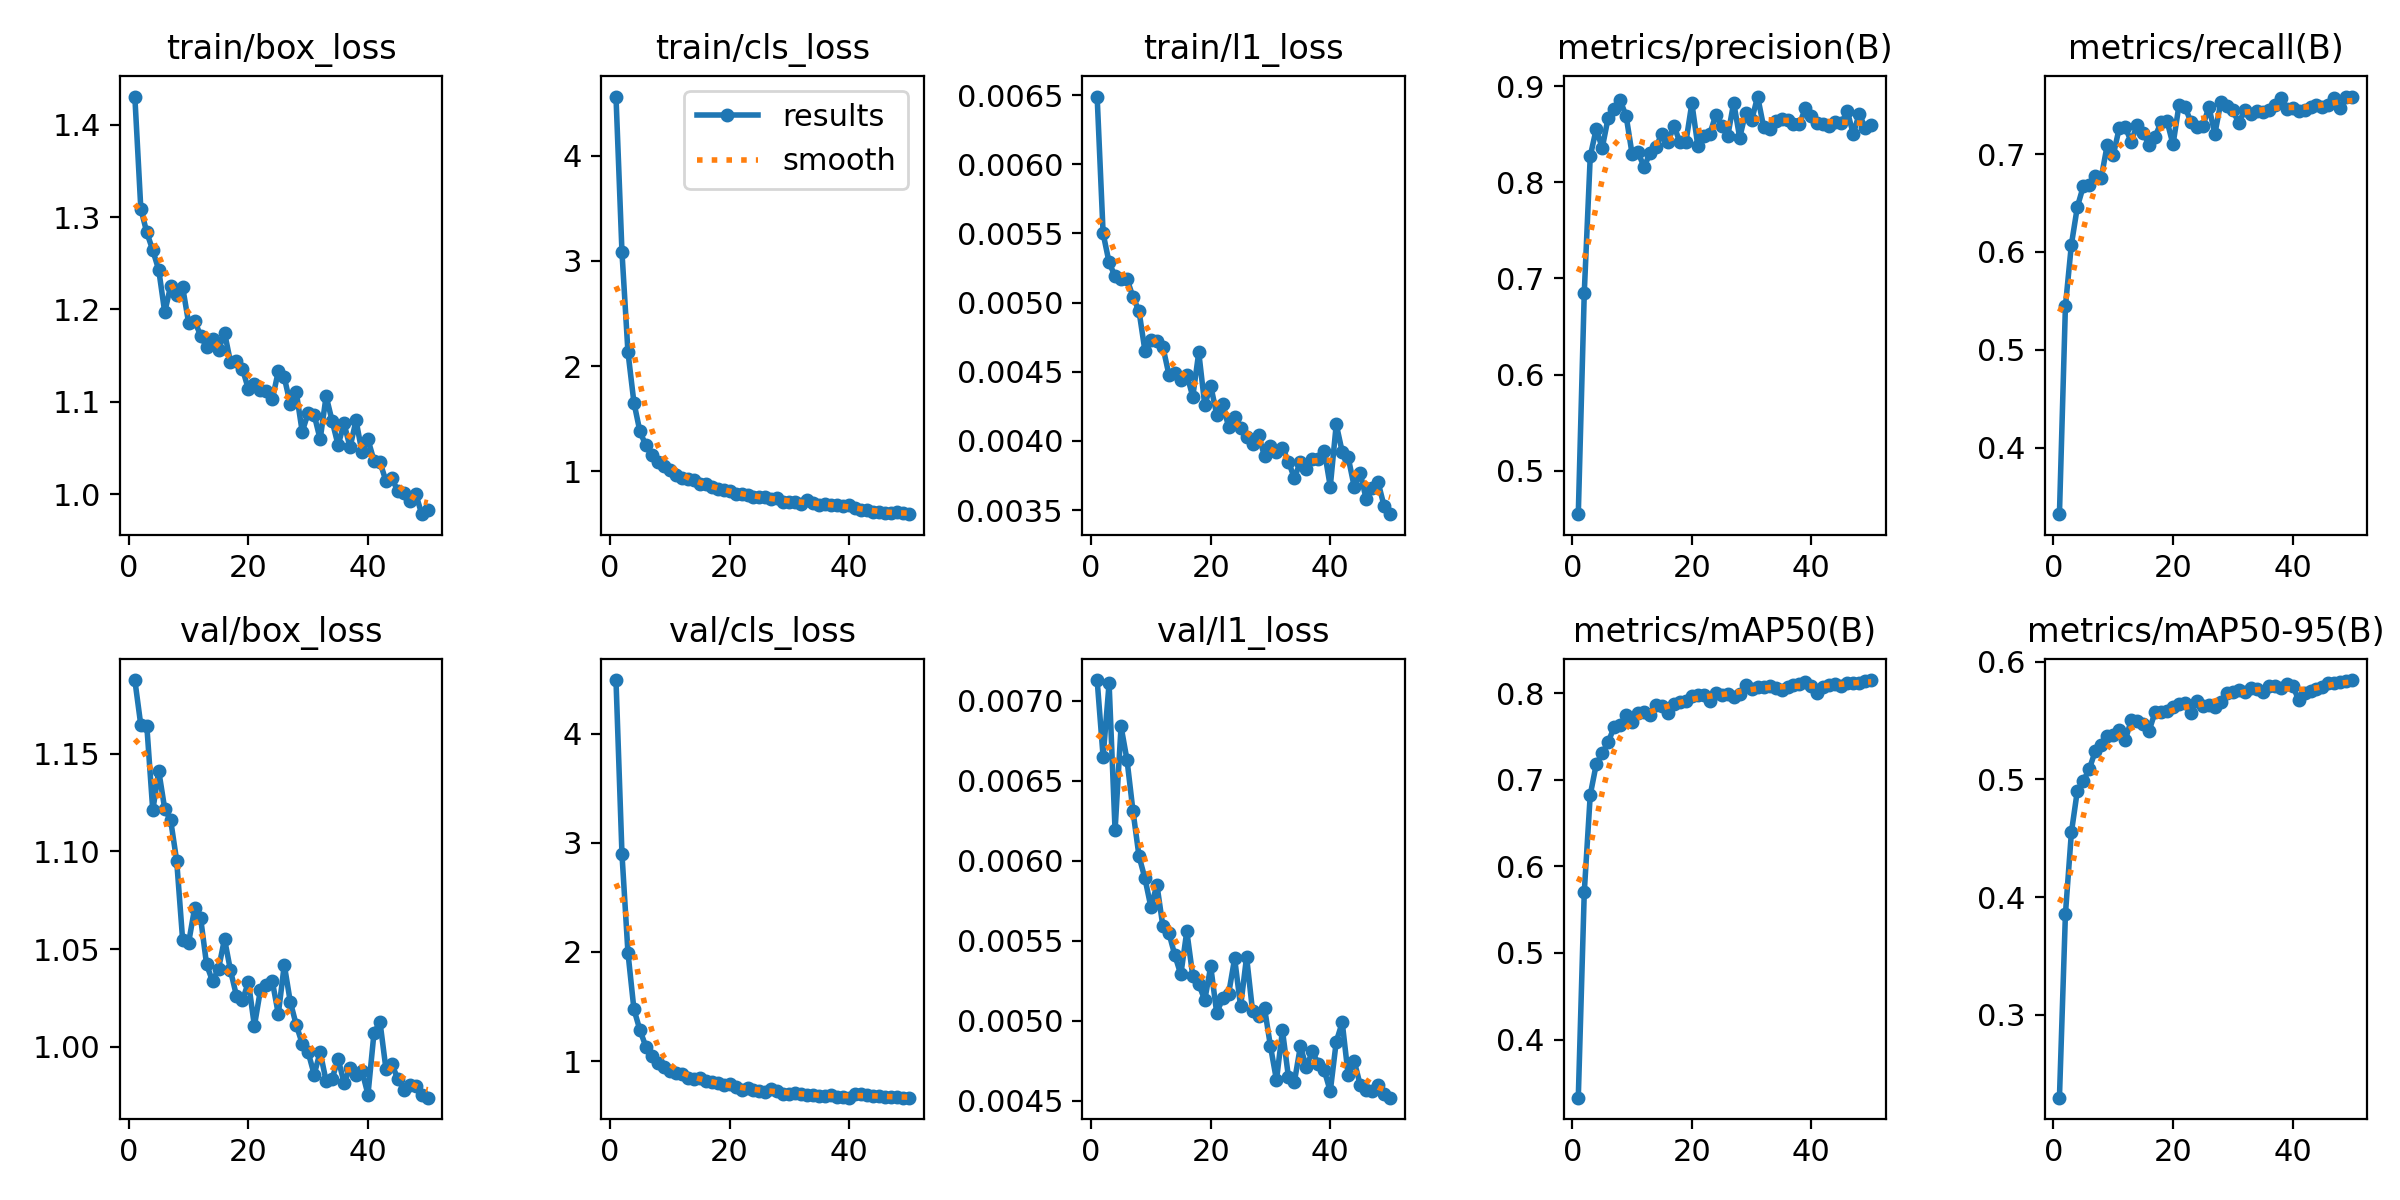

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3855.7±590.1 MB/s, size: 852.4 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 36.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.7it/s 7.5s
                   all        200       2961       0.86      0.757      0.815      0.586
                helmet        146        294      0.927      0.844        0.9      0.719
                gloves        136        381      0.888      0.803       0.86      0.657
                  vest        157        340      0.946      0.909       0.94      0.752
                 boots        155        481      0.825      0.751      0.832      0.638
               goggles      

In [ ]:
from ultralytics import YOLO
from ultralytics.utils.plotting import plot_results
from google.colab import drive
from IPython.display import Image, display
import os
import shutil

drive.mount('/content/drive')

save_dir2 = results.save_dir

plot_results(file=os.path.join(save_dir2, "results.csv"))

display(Image(filename=os.path.join(save_dir2, "results.png")))

model2weights = YOLO(
    os.path.join(save_dir2, "weights", "best.pt")
)

metrics = model2weights.val(
    data=yaml,
    imgsz=960
)

destination = "/content/drive/MyDrive/PPE_Construction_YOLO/weights"

os.makedirs(destination, exist_ok=True)

shutil.copy(
    os.path.join(save_dir2, "weights", "best.pt"),
    os.path.join(destination, "model2.pt")
)

print("Saved files:", os.listdir(destination))

### Results

#### Plotted metrics

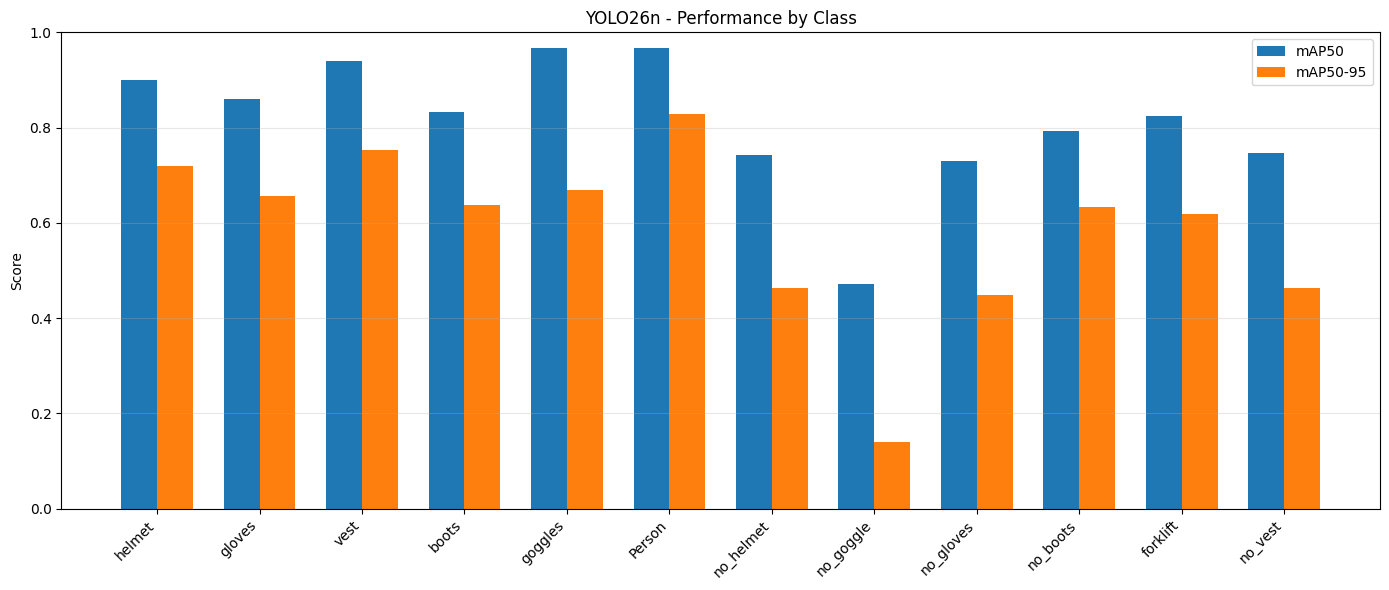

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

names = metrics.names
class_ids = metrics.box.ap_class_index

class_names = [names[int(i)] for i in class_ids]

map50 = metrics.box.ap50
map5095 = metrics.box.maps

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, map50, width, label="mAP50")
plt.bar(x + width/2, map5095, width, label="mAP50-95")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Performance by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

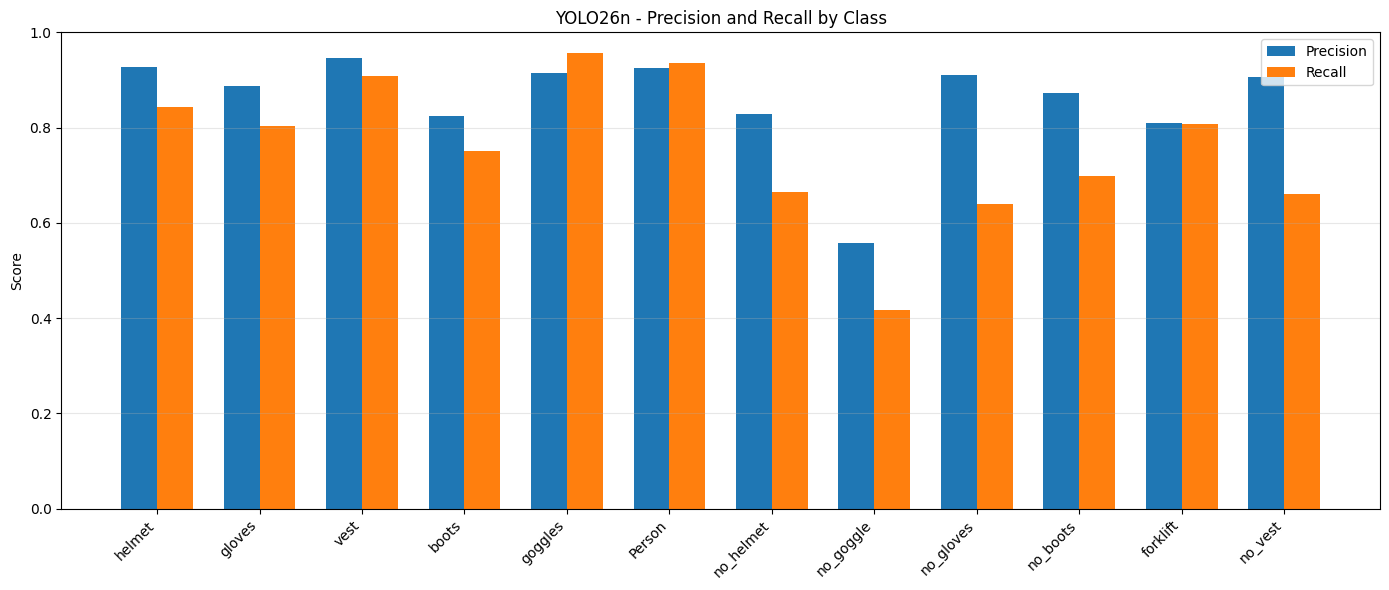

In [ ]:
precision = metrics.box.p
recall = metrics.box.r

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, precision, width, label="Precision")
plt.bar(x + width/2, recall, width, label="Recall")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Precision and Recall by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Visualize predictions

Ground Truth


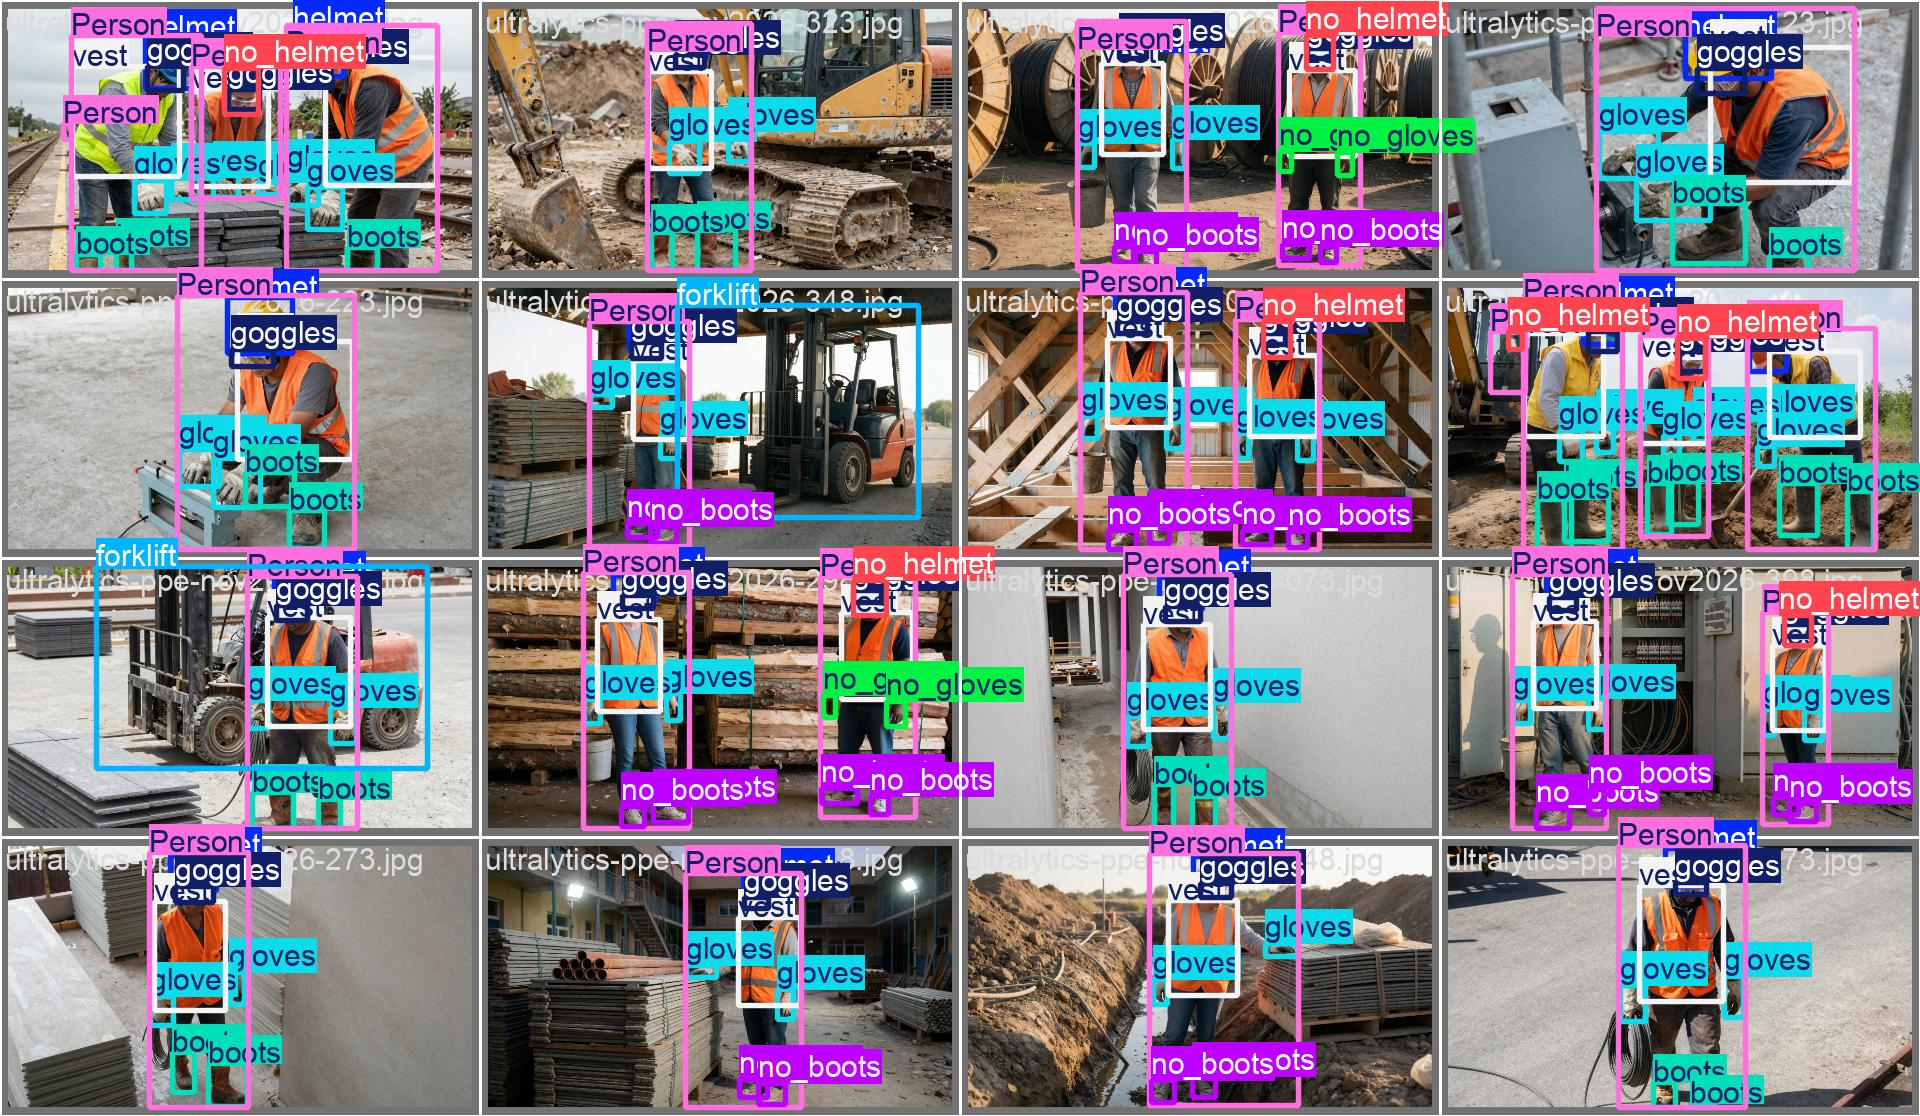

Predictions


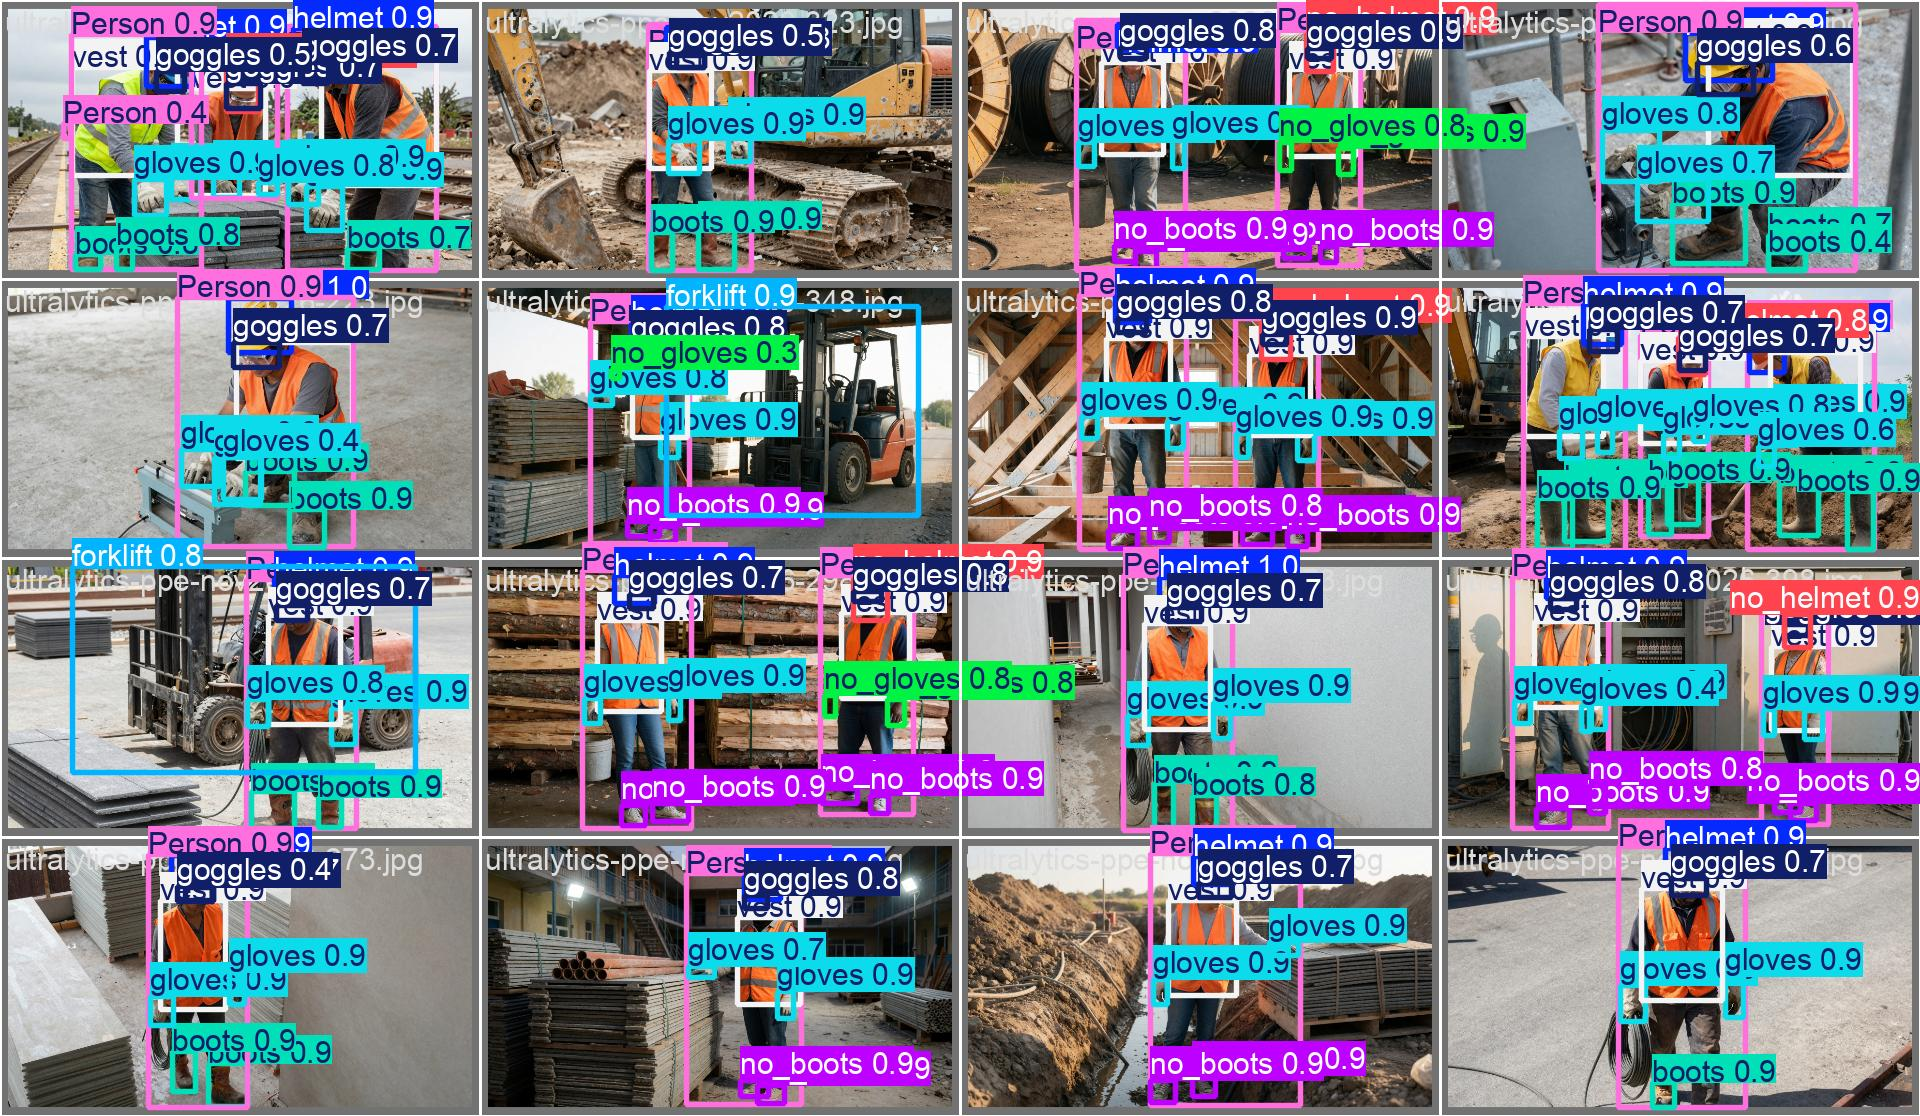

Ground Truth


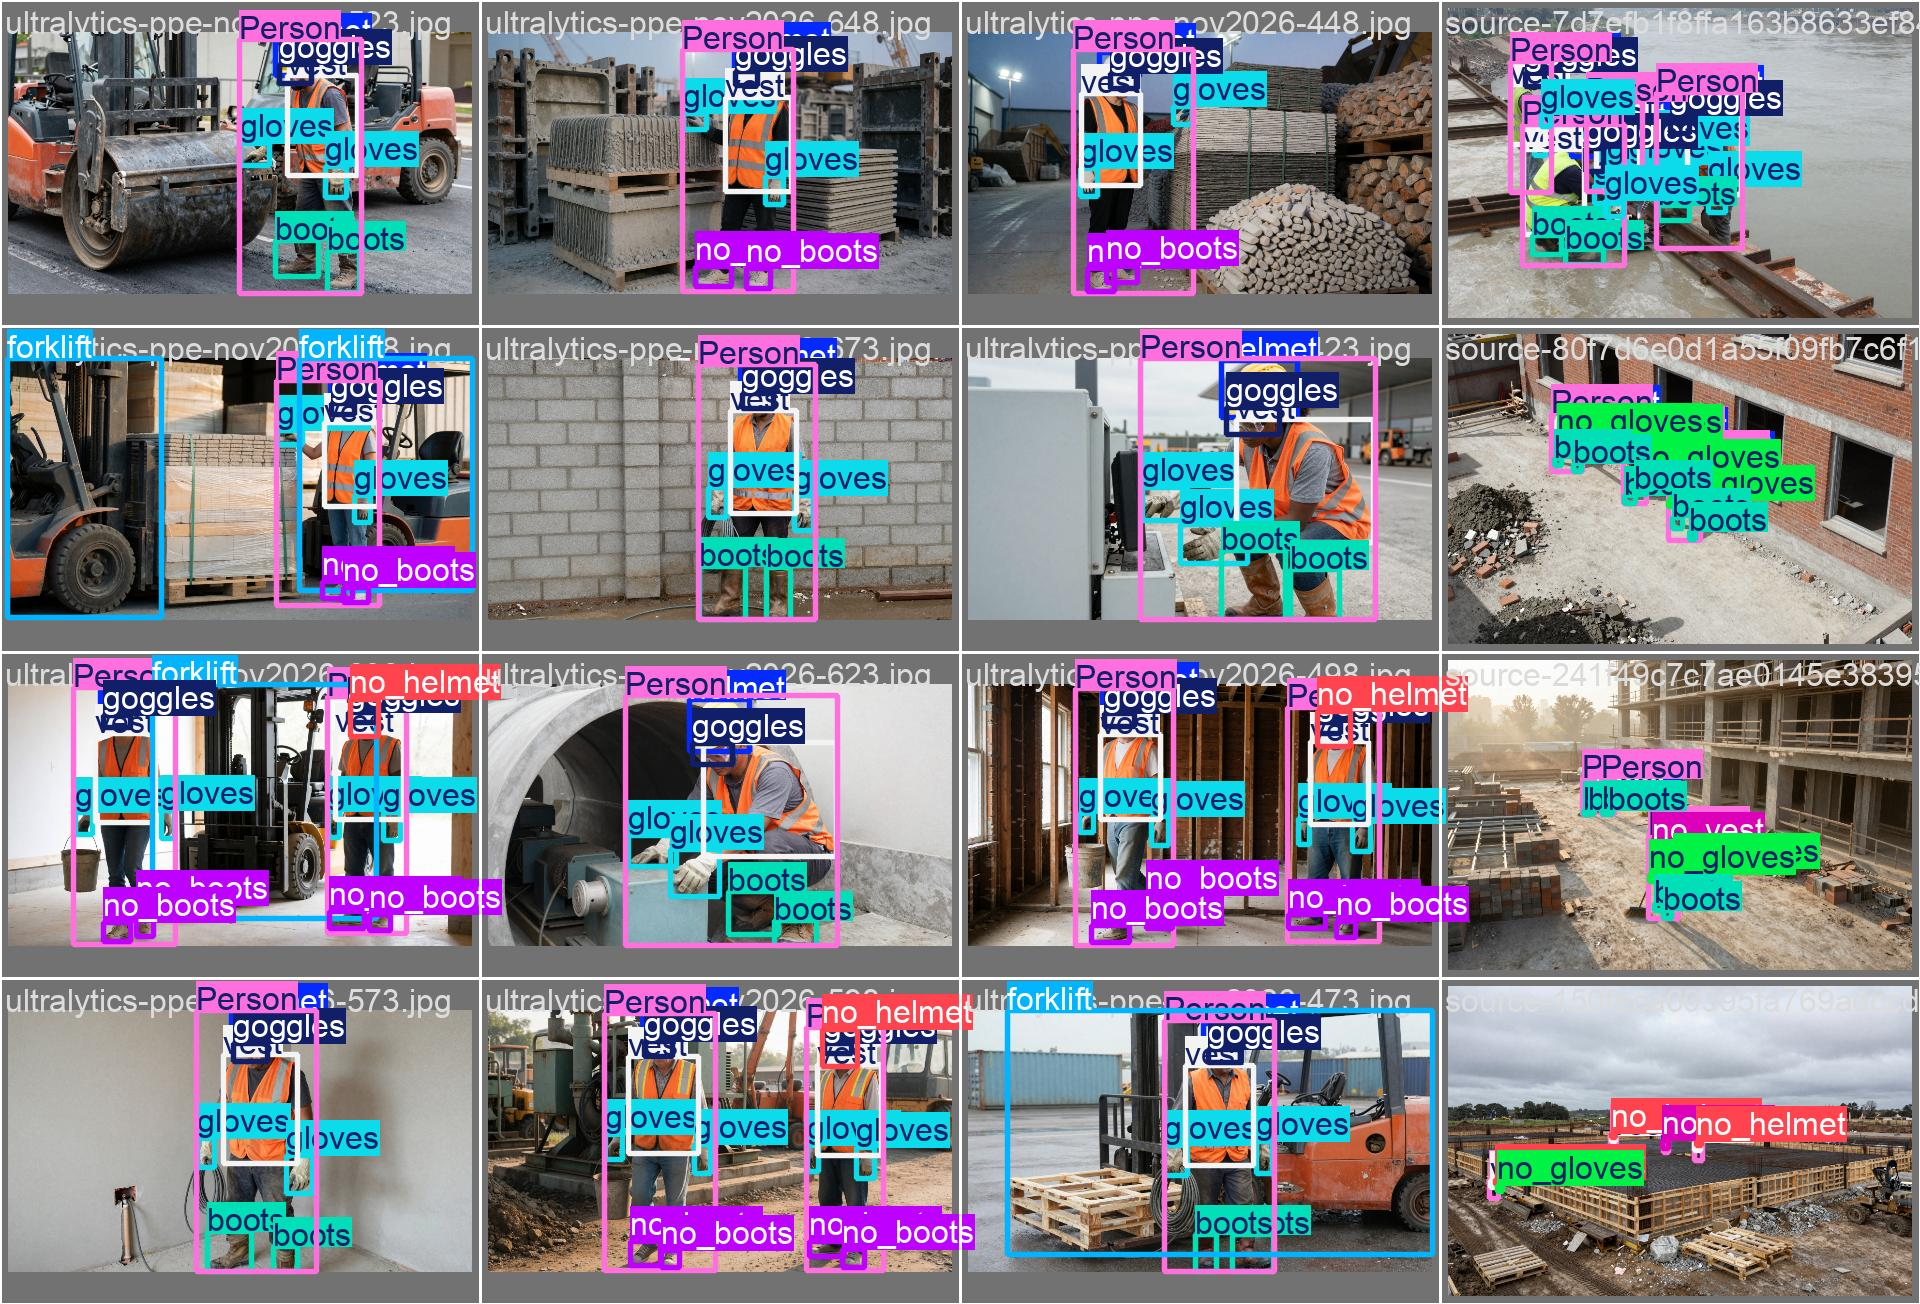

Predictions


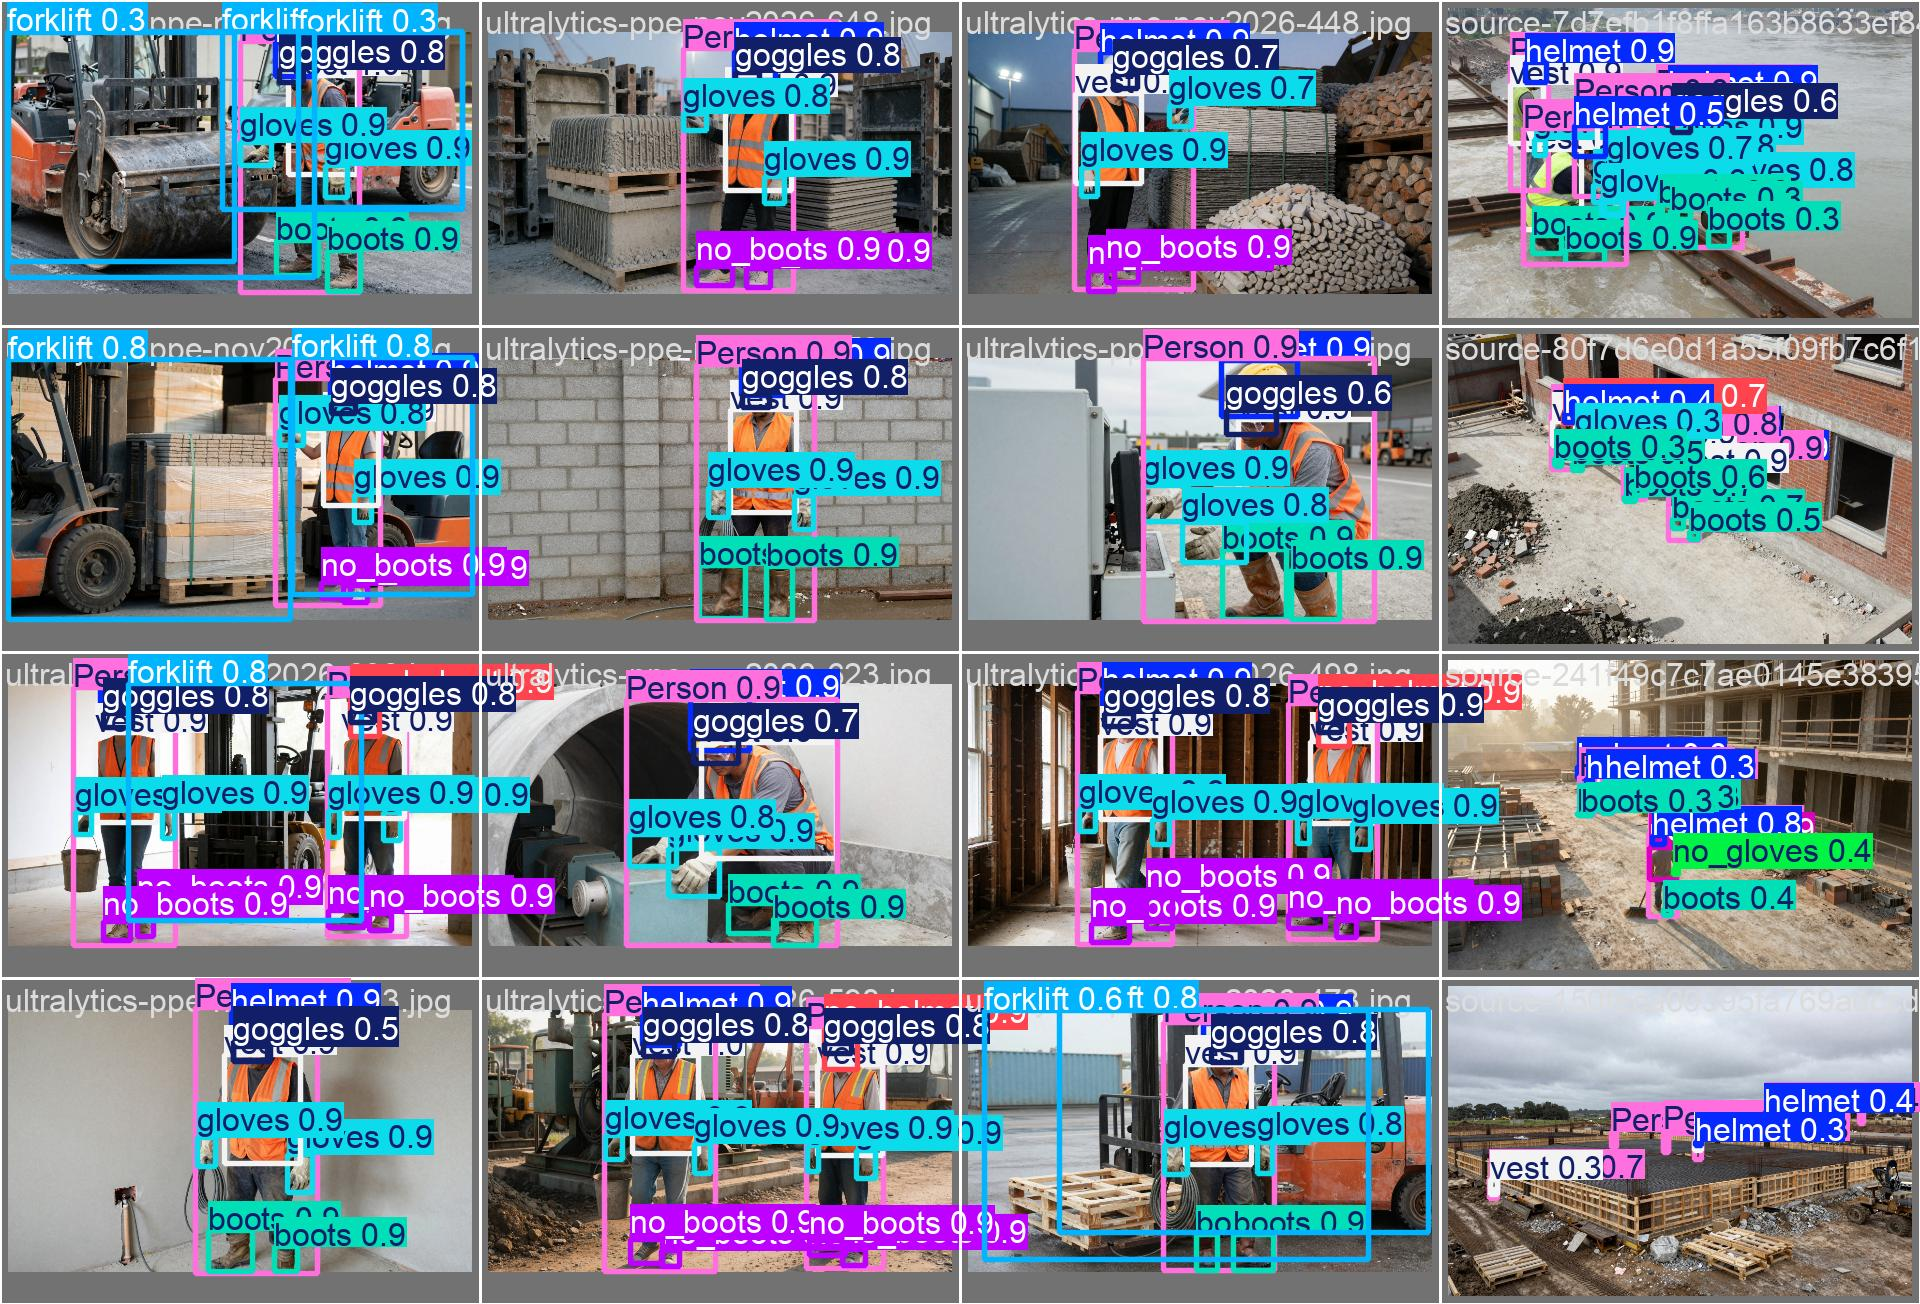

Ground Truth


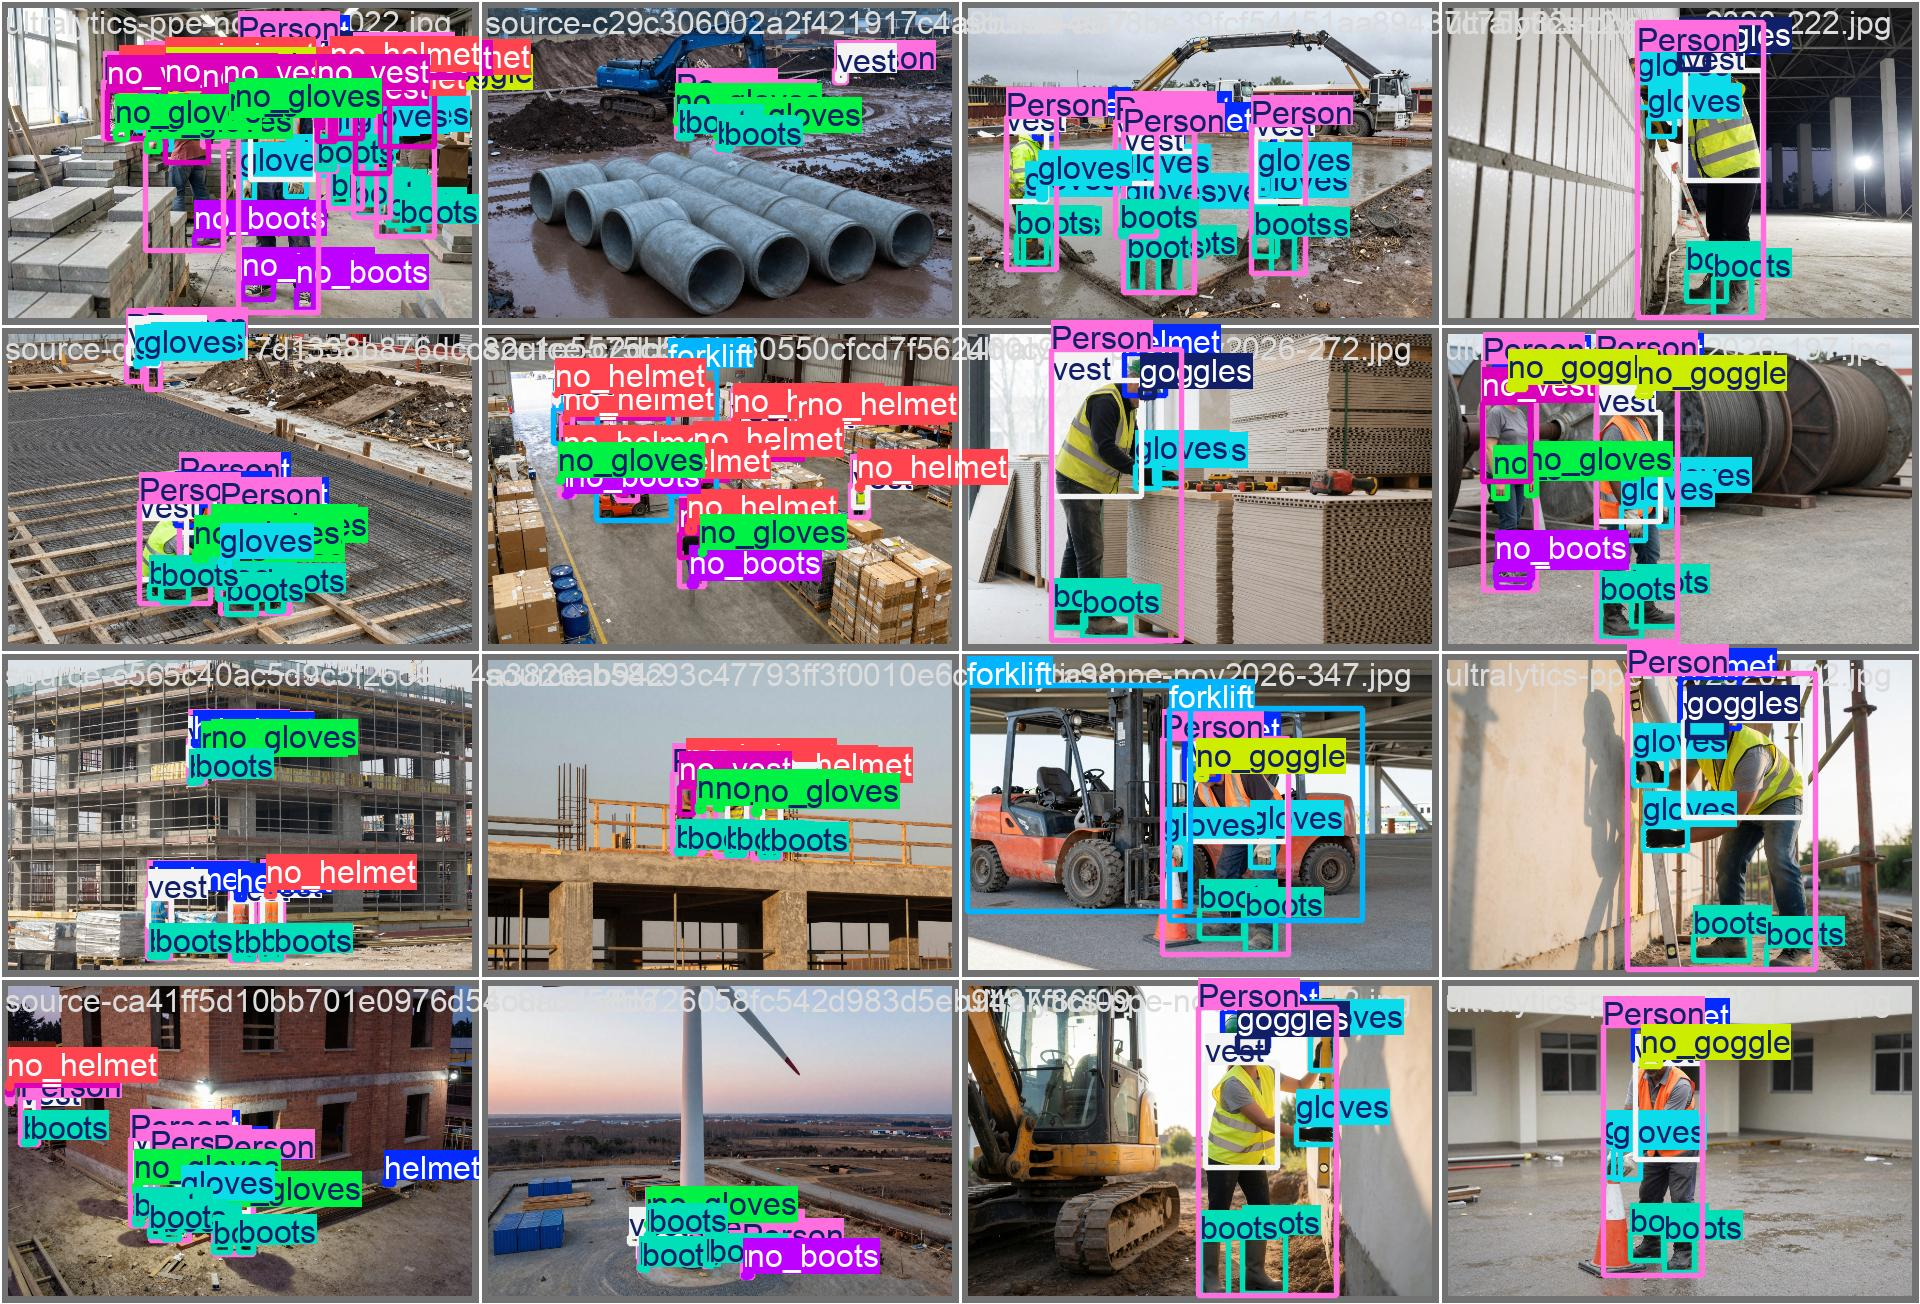

Predictions


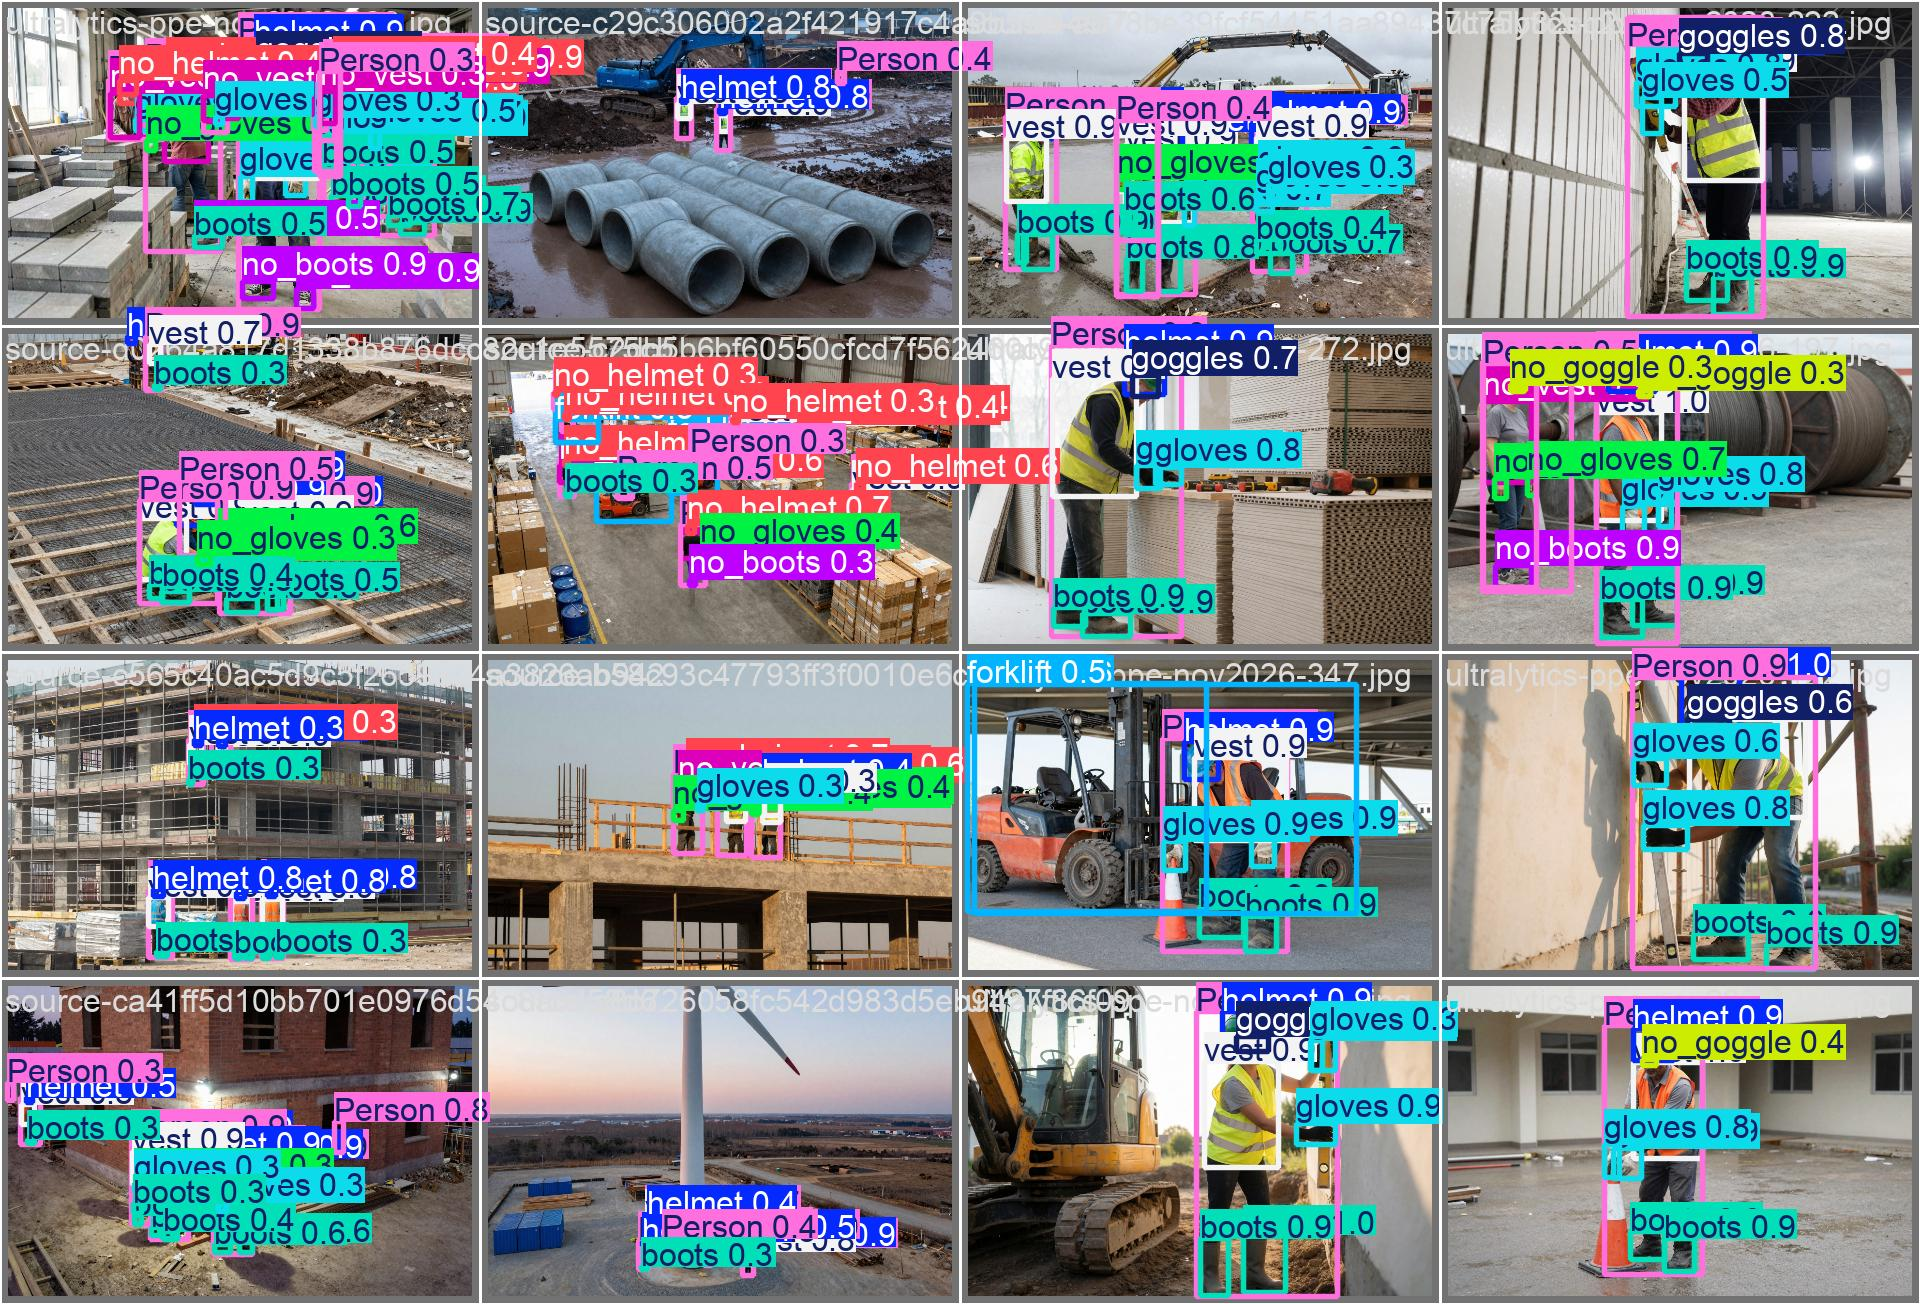

In [ ]:
import glob

label_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_labels.jpg")
)

pred_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_pred.jpg")
)

for label, pred in zip(sorted(label_images), sorted(pred_images)):

    print("Ground Truth")
    display(Image(filename=label))

    print("Predictions")
    display(Image(filename=pred))

#### Observations and Potential Improvements

Increasing the input image resolution from 640 to 960 pixels resulted in an overall improvement in detection performance, with mAP50 increasing from 0.750 to 0.815 and mAP50-95 from 0.537 to 0.580.

A particularly noticeable improvement was observed in classes representing PPE absence. The no_goggle class showed the largest improvement, with its mAP50 increasing from 0.251 to 0.477. Similarly, no_helmet, no_gloves, and no_boots also achieved higher mAP50 scores.

These findings suggest that higher input resolution may help the model capture more detailed visual features, particularly when detecting small PPE-related objects and safety violations.

However, despite this improvement, no_goggle remains the most challenging class, with an mAP50 of 0.477 and an mAP50-95 of 0.140. This indicates that increasing image resolution alone may not be sufficient to address the difficulties associated with detecting this category.

**Potential Further Improvements**

Data augmentation: Explore whether additional training transformations can improve the model's generalization and detection performance across underperforming classes.

Alternative problem formulation: Further explore a presence-only detection approach and investigate whether PPE violations can be inferred by associating detected equipment with individual workers.